# Is infidelity priced in?

When a CEO's affair or sexual misconduct goes public, what happens to the stock? The internet says it goes up (the "affair rally":
Bezos, Gates, Brin). Two published studies say it goes down. This notebook tests it three ways, then looks at Nvidia in November 2026.

**Pre-registration.** The sample rule, the windows, the tests and the verdict rule were written and committed before any return was
computed. Every later change is logged as a dated erratum in `prereg.md`, including two runs I had to redo.

**What's here and what isn't.** The logic lives in the small `e03/` package, which has unit tests (`pytest`). This notebook loads its
outputs and draws the figures. Raw vendor data isn't redistributed: `python -m e03.fetch` downloads it, and `data/manifest.json` holds the checksums.

| Step | Command | Output |
|---|---|---|
| Data | `python -m e03.fetch` | `data/raw/` |
| Events | `python -m e03.events` | `out/events_arm_c.csv` |
| Event study | `python -m e03.run_arm_c` | `out/arm_c.json` |
| Replication | `python -m e03.viral_test` | `out/arm_b_viral.json` |
| Nvidia | `python -m e03.synth --last 2026-11-11` (~25 min, MCMC) | `out/arm_d_nvidia.json` |
| Card | `python -m e03.card` | `out/results_card.json` |

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

OUT = "out/"
load = lambda f: json.load(open(OUT + f))
c, sens, b, d, card = load("arm_c.json"), load("arm_c_sensitivity.json"), load("arm_b_viral.json"), load("arm_d_nvidia.json"), load("results_card.json")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

## 1. The sample

Three famous names is a highlight reel, not a sample. The systematic sample comes from the open CEO-dismissal database of
Gentry, Harrison, Quigley & Boivie (2021, *Strategic Management Journal*): every S&P 1500 CEO exit coded **4, "dismissed for legal
violations or concerns"**. I keep the ones whose notes mention sex or relationships (a keyword rule fixed in advance). Two of the
three viral names fail before we even start: Gates had left Microsoft's board before his 2021 story, and Brin wasn't Google's CEO in 2013.

In [2]:
ev = pd.read_csv(OUT + "events_arm_c.csv")
audit = pd.DataFrame(c["csex_audit"])
funnel = pd.Series({
    "Code 4 dismissals (1993-2024)": len(ev),
    "...notes mention sex/relationship": int(ev.sex_cut.sum()),
    "...with an announcement date": int(ev[ev.sex_cut].event_date.notna().sum()),
    "...with prices (usable)": int((audit.status == "ok").sum()),
})
funnel.to_frame("events")

,events
Code 4 dismissals (1993-2024),237
...notes mention sex/relationship,34
...with an announcement date,27
...with prices (usable),24


## 2. Abnormal returns

For each firm I fit the Fama-French five-factor model on trading days −250 to −30 before the news, predict what the stock should have done
around the news, and keep the difference: the abnormal return. CAR[0,+1] adds up the news day and the day after. The tests are the
Kolari-Pynnönen-adjusted BMP test (pre-registered as primary), Corrado's rank test and the generalized sign test.

In [3]:
rows = []
for model in ["ff5", "mm"]:
    for w, v in c[f"csex_{model}"].items():
        rows.append({"model": model, "window": w, "n": v["n"], "mean CAR": f"{v['mean_car']:+.2%}",
                     "95% CI (KP)": f"[{v['ci95_kp'][0]:+.2%}, {v['ci95_kp'][1]:+.2%}]",
                     "p (KP-BMP)": round(v["p_kp"], 3), "p (rank)": round(v["p_corrado"], 3),
                     "p (sign)": round(v["p_sign_exact"], 3), "fell": v["n"] - v["n_pos"]})
pd.DataFrame(rows)

,model,window,n,mean CAR,95% CI (KP),p (KP-BMP),p (rank),p (sign),fell
0,ff5,0_1,24,-1.92%,"[-3.74%, -0.11%]",0.088,0.003,0.007,19
1,ff5,-1_5,24,-3.45%,"[-6.41%, -0.49%]",0.034,0.006,0.004,19
2,ff5,0_20,24,-2.35%,"[-5.81%, +1.10%]",0.160,0.380,0.540,13
3,mm,0_1,24,-1.92%,"[-3.86%, +0.01%]",0.077,0.008,0.007,19
4,mm,-1_5,24,-3.37%,"[-6.63%, -0.11%]",0.061,0.022,0.225,15
5,mm,0_20,24,-2.02%,"[-5.59%, +1.55%]",0.250,0.520,0.541,13


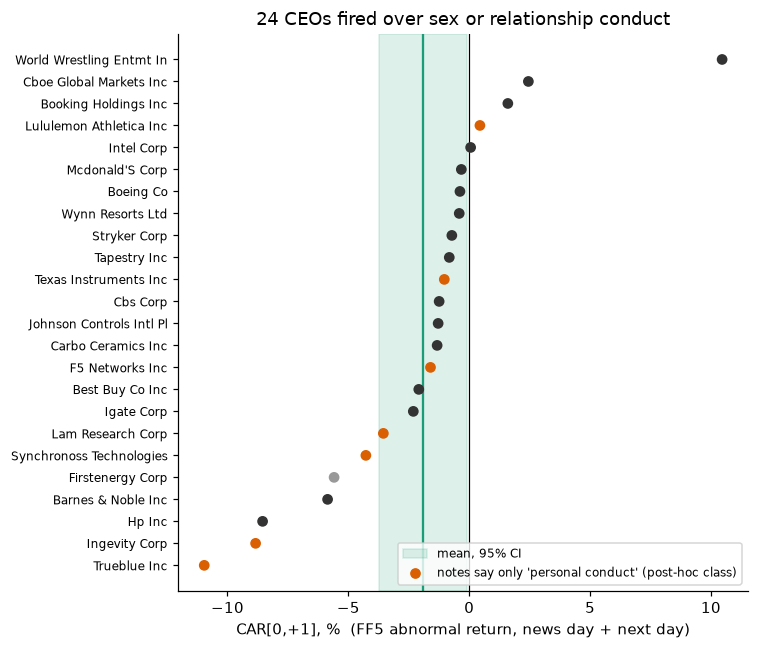

In [4]:
ok = audit[audit.status == "ok"].sort_values("car01")
cls = pd.read_csv(OUT + "csex_manual_audit.csv").set_index("id")["class"]
colors = ok.id.map(cls).map({"S": "#333333", "U": "#d95f02", "N": "#999999"})
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(ok.car01 * 100, range(len(ok)), c=colors, zorder=3)
ax.set_yticks(range(len(ok)), ok.coname.str.title().str[:24], fontsize=8)
p = c["csex_ff5"]["0_1"]
ax.axvline(0, color="k", lw=0.8)
ax.axvspan(p["ci95_kp"][0] * 100, p["ci95_kp"][1] * 100, color="#1b9e77", alpha=0.15, label="mean, 95% CI")
ax.axvline(p["mean_car"] * 100, color="#1b9e77")
ax.set_xlabel("CAR[0,+1], %  (FF5 abnormal return, news day + next day)")
ax.set_title("24 CEOs fired over sex or relationship conduct")
ax.scatter([], [], c="#d95f02", label="notes say only 'personal conduct' (post-hoc class)")
ax.legend(loc="lower right", fontsize=8); plt.tight_layout()

**Verdict under the pre-registered rule: "Contradicted".** The 95% interval is entirely below zero, so the stock falls rather than rallies.
It's close, though. The interval's upper end is −0.1%, and the primary BMP-KP test gives p = 0.09. The rank and sign tests reject
(p = 0.003, 0.007). This lines up with Cline, Walkling & Yore (2018) and Borelli-Kjaer et al. (2021), who both find drops of about 1.5–2%.

**Sensitivity (manual reading of each case's notes, not the verdict).** Cases where the notes clearly describe an affair or harassment
average **−0.7%**. Cases where the company only said "personal conduct" average **−4.3%** (n = 7). I didn't plan this split, so it's a
lead, not a result. It is consistent with Borelli-Kjaer et al.'s finding that self-disclosure softens the reaction.

In [5]:
pd.DataFrame({k: {"n": v["0_1"]["n"], "mean CAR[0,+1]": f"{v['0_1']['mean_car']:+.2%}", "p (KP-BMP)": round(v["0_1"]["p_kp"], 3)}
              for k, v in sens.items()}).T

,n,"mean CAR[0,+1]",p (KP-BMP)
strict_S,16,-0.67%,0.462
S_plus_U,23,-1.76%,0.114


## 3. Replicating a fellow researcher's test

A fellow macro quant researcher posted this test (credit to follow once I've spoken to him): a monthly FF5 regression with a `Post` dummy, 36 months before against 36 after, Newey-West standard errors, its 15 cases. His own
estimate isn't public, so this is "his spec, my run". The assumptions I had to make are listed in `e03/viral_test.py`.

In [6]:
rb = pd.DataFrame(b["cases"])[["case", "event_date", "delta", "t", "p"]]
rb["delta"] = (rb["delta"] * 100).round(2).astype(str) + "%/mo"
display(rb)
print({k: v for k, v in b["summary"].items()})

,case,event_date,delta,t,p
0,Amazon / Bezos,2019-01-09,-1.65%/mo,-1.634121,0.102233
1,Microsoft / Gates,2021-05-16,-0.35%/mo,-0.495231,0.620437
2,SK Hynix / Chey,2015-12-29,1.46%/mo,0.804772,0.420951
3,Alphabet / Brin,2013-08-28,-0.38%/mo,-0.258789,0.795798
4,Boeing / Stonecipher,2005-03-07,0.42%/mo,0.305663,0.759862
5,HP / Hurd,2010-08-06,-3.01%/mo,-1.797009,0.072334
6,Best Buy / Dunn,2012-04-10,5.9%/mo,2.366873,0.017939
7,Lockheed / Kubasik,2012-11-09,1.13%/mo,1.234802,0.216904
8,Priceline / Huston,2016-04-28,-1.45%/mo,-1.068341,0.285367
9,Intel / Krzanich,2018-06-21,-1.36%/mo,-0.934252,0.350174


{'n': 15, 'mean_delta_monthly': -0.002756066909982428, 't_cross': -0.5185839385443359, 'n_positive': 4, 'n_sig_pos_5pct': 1, 'n_sig_neg_5pct': 0, 'reel_only_mean_delta': -0.00227956253006057}


## 4. Nvidia against a synthetic Nvidia

One company can't be averaged, so I build a counterfactual. Nvidia's daily returns are written as a weighted mix of 26 US chip
stocks (Bayesian synthetic control, CausalPy). The weights are fitted on the year before the first report (Oct 29). Then I see how far real Nvidia
drifts from that twin after the Nov 8 letter. For inference I rerun the identical method pretending each of the 26 peers was the treated one.

largest weights: {'TSM': 0.474, 'AVGO': 0.163, 'ADI': 0.038, 'ASML': 0.03, 'TXN': 0.028}


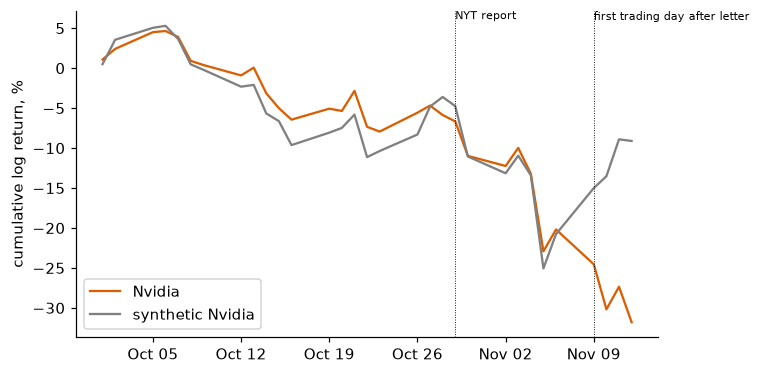

In [7]:
s = pd.DataFrame(d["nvda"]["series"]).set_index("date")
s.index = pd.to_datetime(s.index)
cum = s[["actual", "synthetic"]].loc["2026-10-01":].cumsum()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cum.index, cum.actual, color="#d95f02", label="Nvidia")
ax.plot(cum.index, cum.synthetic, color="grey", label="synthetic Nvidia")
for x, lab in [("2026-10-29", "NYT report"), ("2026-11-09", "first trading day after letter")]:
    ax.axvline(pd.Timestamp(x), color="k", lw=0.6, ls=":"); ax.text(pd.Timestamp(x), ax.get_ylim()[1], lab, fontsize=7, va="top")
import matplotlib.dates as mdates
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d")); ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0))
ax.set_ylabel("cumulative log return, %"); ax.legend(loc="lower left"); plt.tight_layout()
w = d["nvda"]["weights"]; print("largest weights:", {k: round(v, 3) for k, v in sorted(w.items(), key=lambda x: -x[1])[:5]})

{'nvda_rank': 1,
 'of': 27,
 'p_value': 0.037037037037037035,
 'order': ['NVDA',
  'MPWR',
  'TSM',
  'ASML',
  'MCHP',
  'NXPI',
  'COHR',
  'AMD',
  'ENTG',
  'SWKS',
  'LSCC',
  'AVGO',
  'ADI',
  'MU',
  'QCOM',
  'TXN',
  'ARM',
  'AMAT',
  'GFS',
  'INTC',
  'KLAC',
  'TER',
  'ALAB',
  'ON',
  'LRCX',
  'CRDO',
  'MRVL']}

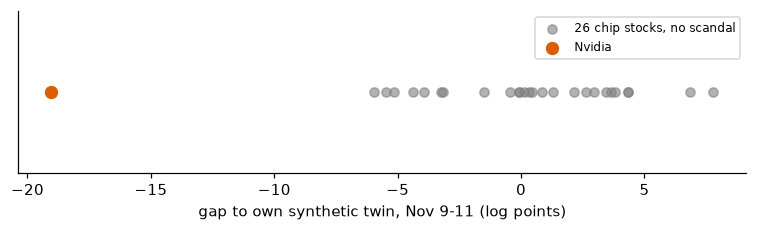

In [8]:
gaps = {k: v["primary_nov9_11"]["gap_pct"] for k, v in d["placebos"].items()}
fig, ax = plt.subplots(figsize=(7, 2.2))
ax.scatter(list(gaps.values()), np.zeros(len(gaps)), color="grey", alpha=0.6, label="26 chip stocks, no scandal")
ax.scatter([d["nvda"]["primary_nov9_11"]["gap_pct"]], [0], color="#d95f02", s=60, label="Nvidia")
ax.set_yticks([]); ax.set_xlabel("gap to own synthetic twin, Nov 9-11 (log points)"); ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); d["placebo_rank"]

In [9]:
# The Nvidia numbers quoted in the video, read straight from the files above (gaps in log points -> simple %).
to_pct = lambda g: f"{np.expm1(g / 100):+.1%}"
h = card["H1_hook_mcap"]
pd.Series({
    "market value lost, Nov 6 -> Nov 12 close ($bn)": h["loss_usd_bn"],
    "chip stocks up on Nov 9": f'{card["L01_hook"]["up"]} of {card["L01_hook"]["of"]}',
    "gap to synthetic twin, Nov 9-11": to_pct(d["nvda"]["primary_nov9_11"]["gap_pct"]),
    "placebo rank": f'{d["placebo_rank"]["nvda_rank"]} of {d["placebo_rank"]["of"]}',
    "gap to twin, Nov 12 (resignation announced)": to_pct(d["nvda"]["side_nov12_ouster_report"]["gap_pct"]),
}, name="value").to_frame()

,value
"market value lost, Nov 6 -> Nov 12 close ($bn)",494
chip stocks up on Nov 9,26 of 27
"gap to synthetic twin, Nov 9-11",-17.3%
placebo rank,1 of 27
"gap to twin, Nov 12 (resignation announced)",-4.1%


**Caveat.** Nov 9–11 carried more than the affair: the Megaspeed export-probe reporting (Nov 9), and after the Nov 11 close a second
reported affair and a WSJ report that the board was preparing to oust Huang. The gap measures that whole package. The windows that include
the later news are declared in erratum E3 and are added after the Nov 12 and Nov 13 closes (windows flagged `complete: false` until then).

## 5. Secondary analyses (pre-registered in §6; specs fixed in errata E4–E5 before they ran)

None of these can change the verdict. Each one asks the same question from a different angle:
- **Calendar-time portfolios:** is there a slow drift over the next 1 to 3 years?
- **GARCH:** is the two-day drop still there once each stock's own volatility regime is allowed for?
- **Abnormal volume:** did the market notice at all?
- **Bayesian model:** how likely is a negative average effect, given the noise in each event?
- **Random dates:** how often do the same 24 firms move this much on ordinary days?

Every secondary p-value (40 of them) goes into one Holm correction.

In [10]:
sec = card["secondary"]
holm = sec["holm"]
pd.DataFrame({k: {"raw p": v[0], "Holm p": v[1]} for k, v in holm["raw_and_adjusted"].items()}).T.sort_values("raw p").head(12)

,raw p,Holm p
volume_csex_w01,0.0000,0.0007
volume_csex_day0,0.0000,0.0010
volume_csex_day1,0.0007,0.0280
eventstudy_csex_ff5_0_1_rank,0.0026,0.0950
eventstudy_call_ff5_-1_5_rank,0.0032,0.1149
eventstudy_call_ff5_-1_5_sign,0.0034,0.1201
eventstudy_csex_ff5_-1_5_sign,0.0037,0.1241
eventstudy_call_ff5_-1_5_kp,0.0038,0.1260
eventstudy_csex_ff5_-1_5_rank,0.0057,0.1833
eventstudy_csex_mm_0_1_sign,0.0066,0.2055


In [11]:
# One table for the stress tests quoted in the video, read straight from the results card.
pd.Series({
    "GARCH-standardized CAR[0,+1]: KP p": sec["garch_scar_csex"]["p_kp"],
    "Bayes: P(average effect < 0)": sec["bayes_csex"]["p_mu_lt0"],
    f'random dates as low as {sec["placebo_dates"]["observed"]}': sec["placebo_dates"]["draws_as_low"],
    "tests in the Holm family": holm["family_size"],
    "survive Holm (all volume)": len(holm["rejected"]),
    "abnormal volume, days 0-1 (s.d.)": sec["volume_csex_day0_1"]["mean"],
    "calendar-time alpha, 36 months": sec["calendar_time_csex"]["36"]["alpha_monthly"],
}, name="value").to_frame()

,value
"GARCH-standardized CAR[0,+1]: KP p",0.101
Bayes: P(average effect < 0),0.968
random dates as low as -1.92%,8 of 1000
tests in the Holm family,40
survive Holm (all volume),3
"abnormal volume, days 0-1 (s.d.)",1.597
"calendar-time alpha, 36 months",-0.03%


{'mu_mean': '-1.12%',
 'hdi94': ['-2.36%', '+0.06%'],
 'p_mu_lt0': 0.968,
 'converged': True,
 'max_rhat': 1.0086,
 'divergences': 24}

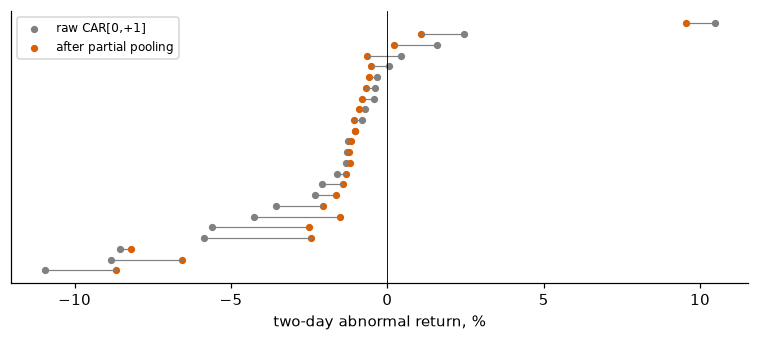

In [12]:
by = json.load(open(OUT + "secondary_bayes.json"))
e = pd.DataFrame(by["events"]).query("group == 'csex'").sort_values("car")
fig, ax = plt.subplots(figsize=(7, 3.2))
for i, (_, r) in enumerate(e.iterrows()):
    ax.plot([r.car * 100, r.theta_mean * 100], [i, i], color="grey", lw=0.8)
ax.scatter(e.car * 100, range(len(e)), color="grey", s=14, label="raw CAR[0,+1]")
ax.scatter(e.theta_mean * 100, range(len(e)), color="#d95f02", s=14, label="after partial pooling")
ax.axvline(0, color="k", lw=0.6); ax.set_yticks([]); ax.set_xlabel("two-day abnormal return, %"); ax.legend(fontsize=8)
plt.tight_layout(); {k: sec["bayes_csex"][k] for k in ("mu_mean", "hdi94", "p_mu_lt0", "converged", "max_rhat", "divergences")}

**What they say.**
- **The market noticed.** Trading volume on the two days runs about 1.6 standard deviations above normal. That's the one secondary result that survives Holm.
- **The price direction is consistently down, but never conclusive on its own:**
  - the GARCH-standardized CAR has KP p ≈ 0.10;
  - the Bayesian model puts P(average effect < 0) at about 0.97. Its 94% interval includes zero (upper end +0.06%), and 24 of 8,000 draws were divergent;
  - only 8 of 1,000 random-date draws for the same firms fell as far as −1.92%;
  - the nearest miss is the rank test on the primary window (raw p 0.003, Holm 0.095);
  - none of the 40 tested p-values on price survives the correction. The Bayesian probability isn't a p-value, so it's outside that family.
- **No slow drift for C-sex.** Calendar-time alpha is indistinguishable from zero at 12 and 36 months.
- **C-all's large positive long-run alpha is not trustworthy.** Its tickers come from today's SEC list, so only survivors are in it.
- **Leave-one-out on the replication:** dropping any one of the 15 cases never turns the average positive. On the 4 viral cases alone, dropping one can (n = 4 is nothing).

Arm B (the replication) contributes one p-value to the Holm family by choice. Volume's day 0, day +1 and two-day mean are one measurement counted three times;
dropping the mean wouldn't change any rejection.

## 6. Limits

- 24 usable events is small. The minimum detectable two-day effect at 80% power is about 2.6%.
- Prices come from Yahoo, plus Tiingo for delisted firms. Four firms have no price source at all, and Execucomp covers only the S&P 1500.
- The keyword rule is crude: one of 24 (FirstEnergy) isn't sexual at all. The pre-registered rule is reported unchanged, with the manual reading as a sensitivity check.
- The Nvidia result is one case in one very noisy week.

In [13]:
card

{'label_rule': 'Historical numbers are in-sample event studies; Nvidia is a single 2026 case.',
 'L01_hook': {'nvda_nov9': '-4.3%',
  'up': 26,
  'of': 27,
  'sox': '+6.9%',
  'source': 'chip_raw_closes_2026-11-03_11.csv'},
 'H1_hook_mcap': {'start': '2026-11-06',
  'end': '2026-11-12',
  'close_start': 186.63999938964844,
  'close_end': 166.19000244140625,
  'shares': 24147000000.0,
  'fetched': '2026-11-13 04:45:05',
  'loss_usd_bn': 494,
  'pct': -10.96,
  'label': 'raw market value, Nov 6 close to Nov 12 close (the resignation day); includes all news that week, not just the affair; current shares outstanding'},
 'L09_grid': {'code4_total': 237,
  'sex_keyword_cut': 34,
  'with_prices_and_date': 24,
  'source': 'Gentry et al. DB v7 code 4; out/events_arm_c.csv'},
 'L14_primary': {'n': 24,
  'mean_car_0_1': '-1.9%',
  'ci95_kp': ['-3.7%', '-0.1%'],
  'n_fell': 19,
  'p_kp': 0.088,
  'p_rank': 0.003,
  'p_sign': 0.007,
  'p_bmp': 0.085,
  't_kp': -1.78,
  'verdict_locked_rule': 'Contr

In [14]:
# The prose above quotes numbers; this cell fails loudly if a rerun ever changes them.
p, s16 = c["csex_ff5"]["0_1"], sens["strict_S"]["0_1"]
assert card["L14_primary"]["verdict_locked_rule"] == "Contradicted"
assert p["n"] == 24 and round(p["ci95_kp"][1] * 100, 1) == -0.1 and round(p["p_kp"], 2) == 0.09
assert (round(p["p_corrado"], 3), round(p["p_sign_exact"], 3)) == (0.003, 0.007)
assert round(s16["mean_car"] * 100, 1) == -0.7 and card["L15_posthoc_twist"]["unspecified_personal_conduct"]["mean_car_0_1"] == "-4.3%"
assert round(p["mde"] * 100, 1) == 2.6
sec = card["secondary"]
assert sec["holm"]["family_size"] == 40 and sec["holm"]["rejected"] == ["volume_csex_day0", "volume_csex_day1", "volume_csex_w01"]
assert sec["bayes_csex"]["hdi94"][1] == "+0.06%" and sec["bayes_csex"]["divergences"] == 24
assert holm["raw_and_adjusted"]["eventstudy_csex_ff5_0_1_rank"] == [0.0026, 0.095]
assert sec["loo_claim_arm_a_monthly"][1].startswith("+")
assert round(sec["volume_csex_day0_1"]["mean"], 1) == 1.6 and round(sec["bayes_csex"]["p_mu_lt0"], 2) == 0.97
assert sec["placebo_dates"]["draws_as_low"] == "8 of 1000" and round(sec["garch_scar_csex"]["p_kp"], 2) == 0.10
assert sec["bayes_csex"]["converged"] and sec["loo_viral_arm_b_monthly"][1].startswith("-")
print("prose matches data")

prose matches data
